# Muon Tomography: Can We Spot High-Z Materials from Muon Scattering? (Draft Project)

> **What this notebook is.** A practice draft that shows what a finished tabular-classification project should look like, step by step, following the course notebook and Lecture 22. It is **not** a Kaggle submission. It uses simple models only (no XGBoost) and plots with matplotlib only.

## Define the project

* **Project link.** Not a Kaggle competition, so there is no link. For a real submission, put the competition URL here.
* **The challenge.** Cosmic-ray muons pass through objects and get bent a little. Heavy materials (high atomic number, "high-Z", like lead and tungsten) bend them more than light ones. The question: **from what we measure about one muon, can we tell whether it passed through a high-Z material?** The paper (Gao et al., *IEEE Transactions on Nuclear Science*, 2025) does this to find hidden nuclear material in cargo.
* **The data.** `muon_labelled_per_muon_in_.csv`: one row per muon, with its scattering angle, track information and a label. The two `dataset` names (`Figure7_lead_shapes`, `Figure10-11_six_materials`) match experiments in the paper. This is a **classification** problem: the target `high_z_threat` is 1 for lead and tungsten and 0 for everything else (carbon, aluminum, iron, copper and plain air).

## Roadmap

1. Look at the file and load it
2. First look: table of features, missing values, class balance
3. Visualize: normalized histograms with identical bins
4. Clean and prepare: what to drop and why, outliers, scaling, one-hot
5. Split into train / validation / test
6. Baselines, then simple models
7. Evaluate (validation to choose, test to report)
8. Sanity check: "too good to be true" features
9. Bridge to the paper: what happens when we combine many muons?
10. Summary

## Settings

Every choice lives in this one cell. Nothing below types a column name, a split size or a model setting again, so to reuse the notebook on another dataset you change only this cell.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import ks_2samp
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

%matplotlib inline

# ---------------- data ----------------
DATA_PATH = Path("muon_labelled_per_muon_in_.csv")   # keep the csv next to this notebook
TARGET = "high_z_threat"                              # 1 = high-Z material, 0 = anything else
BOOKKEEPING = ["muon_id", "file_no"]                  # counters, never features
TIME_COLUMN = "time_min"                              # when the muon arrived
EXPERIMENT_COLUMN = "dataset"                         # which experiment it came from
OBJECT_COLUMN = "object"                              # what it passed through (used to group muons)
LOCATION_PATTERN = r"^(poca_|track_|[xyz]\d_mm$)"     # columns that say WHERE, not WHAT
MAX_CATEGORIES = 20                                   # at most this many values = treat as a category

# ---------------- outlier check (PoCA point outside the detector) ----------------
AXES = ["x", "y", "z"]
POCA_TEMPLATE = "poca_{axis}_mm"
HIT_TEMPLATE = r"{axis}\d_mm"                         # regular expression for the hit columns

# ---------------- split, plots, models ----------------
SPLIT = {"train": 0.8, "validation": 0.1, "test": 0.1}
SEED = 42
BINS = 50
PLOT_RANGE_QUANTILES = (0.005, 0.995)   # only trims the x-axis of a plot, never removes data
MAP_COLUMNS = ["track_x_mid_mm", "track_y_mid_mm"]
MAP_SAMPLE = 20000
TREE_DEPTHS = [2, 3, 4, 5, 6, 8, 10, 14]
FOREST_TREES = 100
FOREST_MIN_LEAF = 50
MAX_ITER = 1000
THRESHOLD = 0.5            # score above this = "flag it"
FALSE_ALARM_RATE = 0.05    # how many harmless muons we allow ourselves to flag

# ---------------- time-window section ----------------
WINDOW_MINUTES = [0.5, 1, 2, 5, 10]
MIN_MUONS_PER_WINDOW = 2

assert abs(sum(SPLIT.values()) - 1) < 1e-9, "the split fractions must add up to 1"

## Helper functions

Small functions used again and again. In a finished project these move into a `.py` module that notebooks import, as in Lecture 22 ("write it in a nice piece of code, checkpoint yourself"). For a single draft notebook they can live here.

In [2]:
def look_at_file(path, n_lines=3):
    """Peek at the raw file before loading it: size, line count, first lines."""
    with open(path) as f:
        head = [next(f).rstrip("\n") for _ in range(n_lines)]
        total = n_lines + sum(1 for _ in f)
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB, {total} lines (1 header + {total - 1} rows)")
    for line in head:
        print("  ", line[:110] + ("..." if len(line) > 110 else ""))


def feature_table(df, roles):
    """One row per column: role, type, how many values, missing, range."""
    rows = []
    for c in df.columns:
        s = df[c]
        numeric = pd.api.types.is_numeric_dtype(s)
        note = ""
        if numeric and s.max() - s.min() == 0:
            note = "constant"
        elif numeric and s.nunique() <= MAX_CATEGORIES:
            note = "few values: really a category?"
        rows.append({"column": c, "role": roles.get(c, "?"),
                     "type": "numerical" if numeric else "categorical",
                     "n_unique": s.nunique(), "missing": int(s.isna().sum()),
                     "min": s.min() if numeric else "", "max": s.max() if numeric else "",
                     "note": note})
    return pd.DataFrame(rows)


def find_label_leaks(df, target, max_categories):
    """Columns with few distinct values where every value belongs to ONE class: they give the answer away."""
    leaks = []
    for c in df.columns.drop(target):
        if df[c].nunique() <= max_categories:
            if df.groupby(c, dropna=False)[target].nunique().max() == 1:
                leaks.append(c)
    return leaks


def compare_hist(df, columns, target, bins, quantiles, ncols=3):
    """Normalized histograms (density=True) of each column for each class, with the SAME bin edges."""
    classes = sorted(df[target].unique())
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.2 * nrows), squeeze=False)
    for ax in axes.ravel()[len(columns):]:
        ax.axis("off")
    for ax, col in zip(axes.ravel(), columns):
        lo, hi = df[col].quantile(quantiles)
        edges = np.linspace(lo, hi, bins + 1)
        for cls in classes:
            ax.hist(df.loc[df[target] == cls, col], bins=edges, density=True,
                    histtype="step", label=f"{target} = {cls}")
        ax.set_xlabel(col)
        ax.set_ylabel("density")
    axes.ravel()[0].legend()
    fig.tight_layout()
    plt.show()


def ks_table(df, columns, target):
    """How different are the two classes' distributions? 0 = identical, 1 = completely separate."""
    c0, c1 = sorted(df[target].unique())
    out = {c: ks_2samp(df.loc[df[target] == c0, c], df.loc[df[target] == c1, c]).statistic for c in columns}
    return pd.Series(out, name="KS statistic").sort_values(ascending=False)


def outside_detector(df, axes, poca_template, hit_template):
    """True where the PoCA point lies outside the box spanned by the detector hits."""
    outside = pd.Series(False, index=df.index)
    for a in axes:
        hits = [c for c in df.columns if re.fullmatch(hit_template.format(axis=a), c)]
        lo, hi = df[hits].min().min(), df[hits].max().max()
        poca = df[poca_template.format(axis=a)]
        outside |= (poca < lo) | (poca > hi)
    return outside


def three_way_split(df, target, fractions, seed):
    """Stratified train / validation / test split (class fractions stay the same in each part)."""
    train, rest = train_test_split(df, train_size=fractions["train"], stratify=df[target], random_state=seed)
    val_share = fractions["validation"] / (fractions["validation"] + fractions["test"])
    val, test = train_test_split(rest, train_size=val_share, stratify=rest[target], random_state=seed)
    return train, val, test


def evaluate(y, score, false_alarm_rate, threshold):
    """AUC, recall at a fixed false-alarm rate, and the usual numbers at one threshold."""
    fpr, tpr, _ = roc_curve(y, score)
    pred = score >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=np.unique(y)).ravel()
    return {"AUC": roc_auc_score(y, score),
            "recall@FA": float(np.interp(false_alarm_rate, fpr, tpr)),
            "accuracy": (tp + tn) / len(y),
            "recall": tp / (tp + fn),
            "precision": tp / (tp + fp) if tp + fp else np.nan}


def make_windows(df, group_cols, time_col, minutes, feature_cols, target, min_muons):
    """One row per (experiment, object, time slot): mean and std of each feature over the muons in it."""
    slot = np.floor(df[time_col] / minutes).rename("slot")
    g = df.groupby(group_cols + [slot])
    stats = g[feature_cols].agg(["mean", "std"])
    stats.columns = [f"{a}_{b}" for a, b in stats.columns]
    stats["n_muons"] = g.size()
    stats[target] = g[target].max()
    return stats[stats["n_muons"] >= min_muons].dropna().reset_index(drop=True)

## 1. Look at the file, then load it

Look before loading: the header, the first rows and how many lines there are. (The size matters: a very large file would need to be cut down.)

In [3]:
assert DATA_PATH.exists(), f"Put {DATA_PATH.name} in the same folder as this notebook"
look_at_file(DATA_PATH)

muon_labelled_per_muon_in_.csv: 33.7 MB, 149557 lines (1 header + 149556 rows)
   dataset,muon_id,file_no,time_min,object,material,atomic_number_Z,z_class,high_z_threat,theta_mrad,theta_x_mrad...
   Figure7_lead_shapes,2,2,0.167,Pb_cylinder,Pb,82,high,1,19.407,20.225,2.397,-297.704,-227.535,256.423,1.767,20....
   Figure7_lead_shapes,69,2,0.167,Pb_cylinder,Pb,82,high,1,80.161,-77.682,-26.347,-109.718,-46.54,861.964,2.894,1...


In [4]:
df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]:,} rows (muons) and {df.shape[1]} columns")
print("duplicate rows:", int(df.duplicated().sum()))
missing = df.isna().sum()
print("columns with missing values:")
display(missing[missing > 0].to_frame("missing"))

149,556 rows (muons) and 31 columns
duplicate rows: 0


columns with missing values:


,missing
atomic_number_Z,49916


## 2. First look

### What the columns mean

| Columns | Meaning |
|---|---|
| `theta_mrad`, `theta_x_mrad`, `theta_y_mrad` | The scattering angle: how much the muon's path bent, in milliradians (total, and its x and y parts). **The key physics measurement.** |
| `dca_mm` | Distance of closest approach between the incoming and outgoing track (mm). A measure of how cleanly the two tracks meet. |
| `zenith_in_deg` | Angle of the incoming muon from straight down (degrees). |
| `poca_*`, `track_*_mid_mm`, `x1_mm` ... `z4_mm` | **Where** things happened: the Point of Closest Approach, where the track crosses the middle, and the detector hits. |
| `object`, `material`, `atomic_number_Z`, `z_class` | **What** the muon passed through. These are the answer in different clothes. |
| `muon_id`, `file_no`, `time_min`, `dataset` | Counters, arrival time and experiment name. |

### Is there class imbalance? What is the target?

In [5]:
counts = df[TARGET].value_counts().sort_index()
table = pd.DataFrame({"muons": counts, "fraction": (counts / counts.sum()).round(3)})
display(table)
print("What each object contributes to each class:")
display(pd.crosstab(df[OBJECT_COLUMN], df[TARGET]))

,muons,fraction
high_z_threat,,
0,109983,0.735
1,39573,0.265


What each object contributes to each class:


high_z_threat,0,1
object,,
Air_1,21213,0
Air_2,19012,0
Air_3,9691,0
Al_cube,15855,0
C_cube,14427,0
Cu_cube,14308,0
Fe_cube,15477,0
Pb_cube,0,20480
Pb_cylinder,0,8301


The target is encoded as 0 and 1. The classes are **imbalanced**: far fewer muons passed through high-Z material than through everything else. That matters twice: **accuracy is misleading** (always answering "0" already scores well), so we will also look at recall and at the ROC curve, and we will try class weights.

### Sorting the columns into roles

Instead of choosing by hand, the code finds the roles from the data and from the settings:

* **Label leaks**: a column with few values where each value belongs to a single class (found automatically).
* **Constants**: nothing to learn from.
* **Bookkeeping**: counters, time and experiment name.
* **Location**: matched by the pattern in the settings.
* Everything left over is a candidate **feature**.

In [6]:
leaks = find_label_leaks(df, TARGET, MAX_CATEGORIES)
constants = [c for c in df.select_dtypes("number").columns if np.isclose(df[c].min(), df[c].max())]
bookkeeping = BOOKKEEPING + [TIME_COLUMN, EXPERIMENT_COLUMN]
location = [c for c in df.columns if re.search(LOCATION_PATTERN, c)]

roles = {}                                  # earlier roles win
for name, cols in [("target", [TARGET]), ("label leak: gives the answer away", leaks),
                   ("constant", constants), ("bookkeeping", bookkeeping),
                   ("location: where, not what", location)]:
    for c in cols:
        roles.setdefault(c, name)
candidates = [c for c in df.columns if c not in roles]
roles.update({c: "feature" for c in candidates})

print("label leaks found automatically:", leaks)
display(feature_table(df, roles))

label leaks found automatically: ['object', 'material', 'atomic_number_Z', 'z_class']


,column,role,type,n_unique,missing,min,max,note
0,dataset,bookkeeping,categorical,2,0,,,
1,muon_id,bookkeeping,numerical,147237,0,2,1593374,
2,file_no,bookkeeping,numerical,4994,0,2,5000,
3,time_min,bookkeeping,numerical,4994,0,0.167,833.167,
4,object,label leak: gives the answer away,categorical,10,0,,,
5,material,label leak: gives the answer away,categorical,7,0,,,
6,atomic_number_Z,label leak: gives the answer away,numerical,6,49916,6.0,82.0,few values: really a category?
7,z_class,label leak: gives the answer away,categorical,4,0,,,
8,high_z_threat,target,numerical,2,0,0,1,few values: really a category?
9,theta_mrad,feature,numerical,67189,0,0.026,1514.086,


**What this table tells us**

* The columns that name the material (`object`, `material`, `atomic_number_Z`, `z_class`) are label leaks. Using them would be like grading a test with the answer key. `atomic_number_Z` is also the only column with missing values, because plain air has no atomic number.
* The four detector-height columns (`z1_mm` to `z4_mm`) never change, so they carry nothing.
* **Location columns are treated separately on purpose.** In this experiment every object sits at a fixed spot, so *where* a muon passed can name the object. Section 8 tests this. For now they are set aside, and the physics measurements are our features.

## 3. Visualize

Normalized histograms (`density=True`), with the same bin edges for both classes. Normalizing lets us compare shapes even though one class is much bigger. The x-axis is trimmed to the quantiles in the settings so long tails don't squash the picture; **no data is removed**.

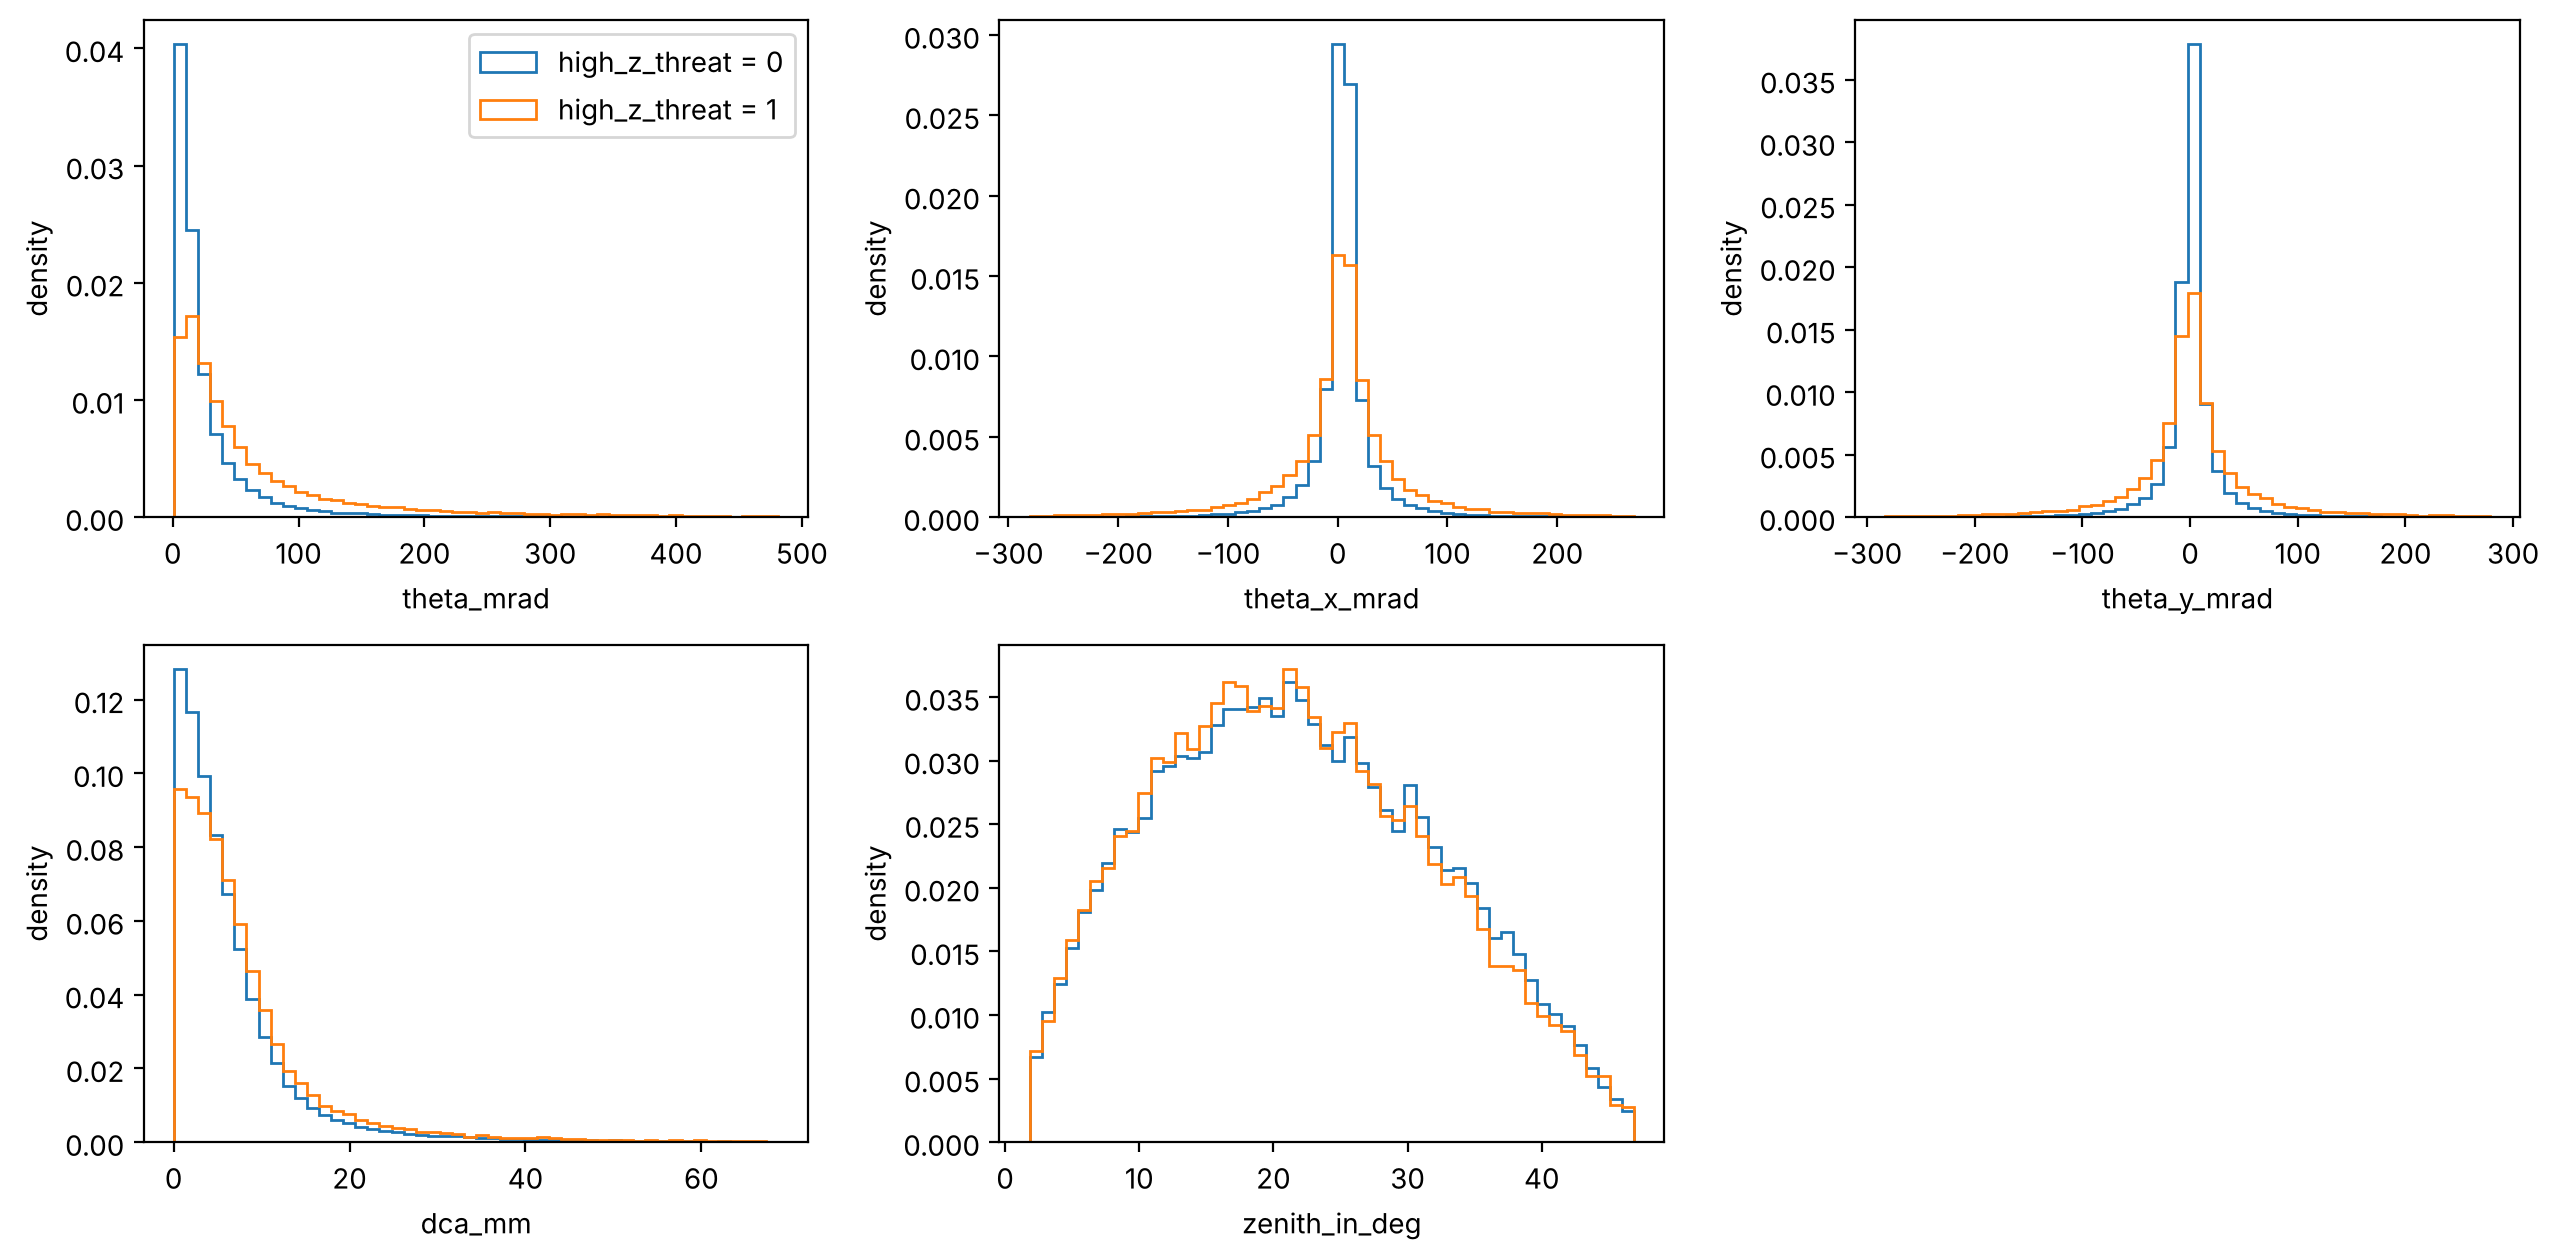

In [7]:
compare_hist(df, candidates, TARGET, BINS, PLOT_RANGE_QUANTILES)

**Notes.** The scattering-angle features (`theta_*`) have the clearest difference: the high-Z class has a wider spread and a heavier tail, as the physics says. Each distribution is a mix of many muons with different energies, so the two classes still overlap a lot. `dca_mm` differs a little. `zenith_in_deg` is nearly identical for both classes, as expected: it describes where the muon came from, not what it hit.

To rank the features, use the KS statistic (as in the lecture): 0 means the two class distributions are identical and 1 means completely separate.

,KS statistic
theta_mrad,0.315
theta_y_mrad,0.148
theta_x_mrad,0.144
dca_mm,0.093
zenith_in_deg,0.018


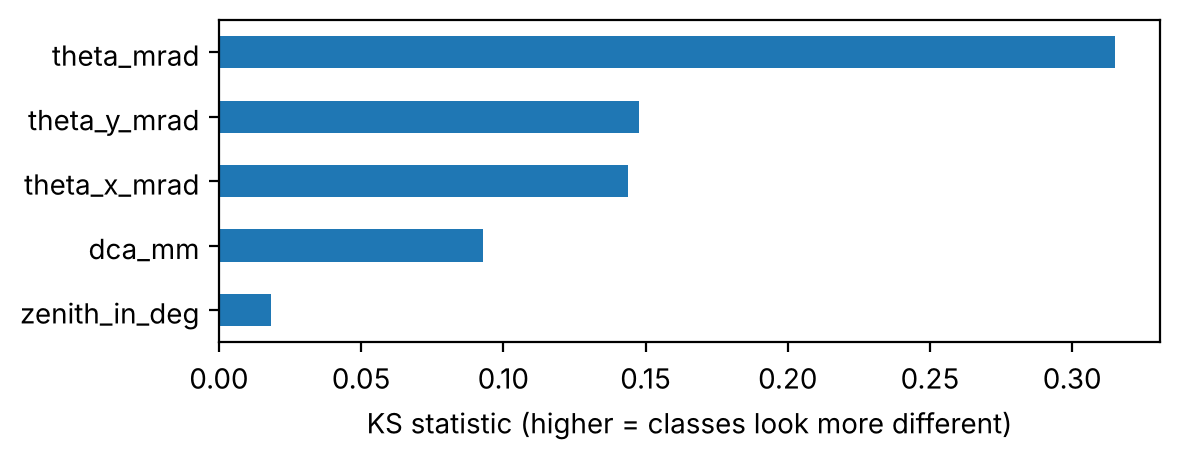

In [8]:
ks_features = ks_table(df, candidates, TARGET)
display(ks_features.round(3).to_frame())
ax = ks_features.sort_values().plot.barh(figsize=(6, 2.4))
ax.set_xlabel("KS statistic (higher = classes look more different)")
plt.tight_layout()
plt.show()

The total scattering angle separates the classes best, and a single muon's angle is a noisy measurement, so we should not expect a perfect score from one muon. Compare with the location features, the ones we set aside:

,KS statistic
track_x_mid_mm,0.616
x3_mm,0.478
track_y_mid_mm,0.455
y3_mm,0.439
poca_x_mm,0.418


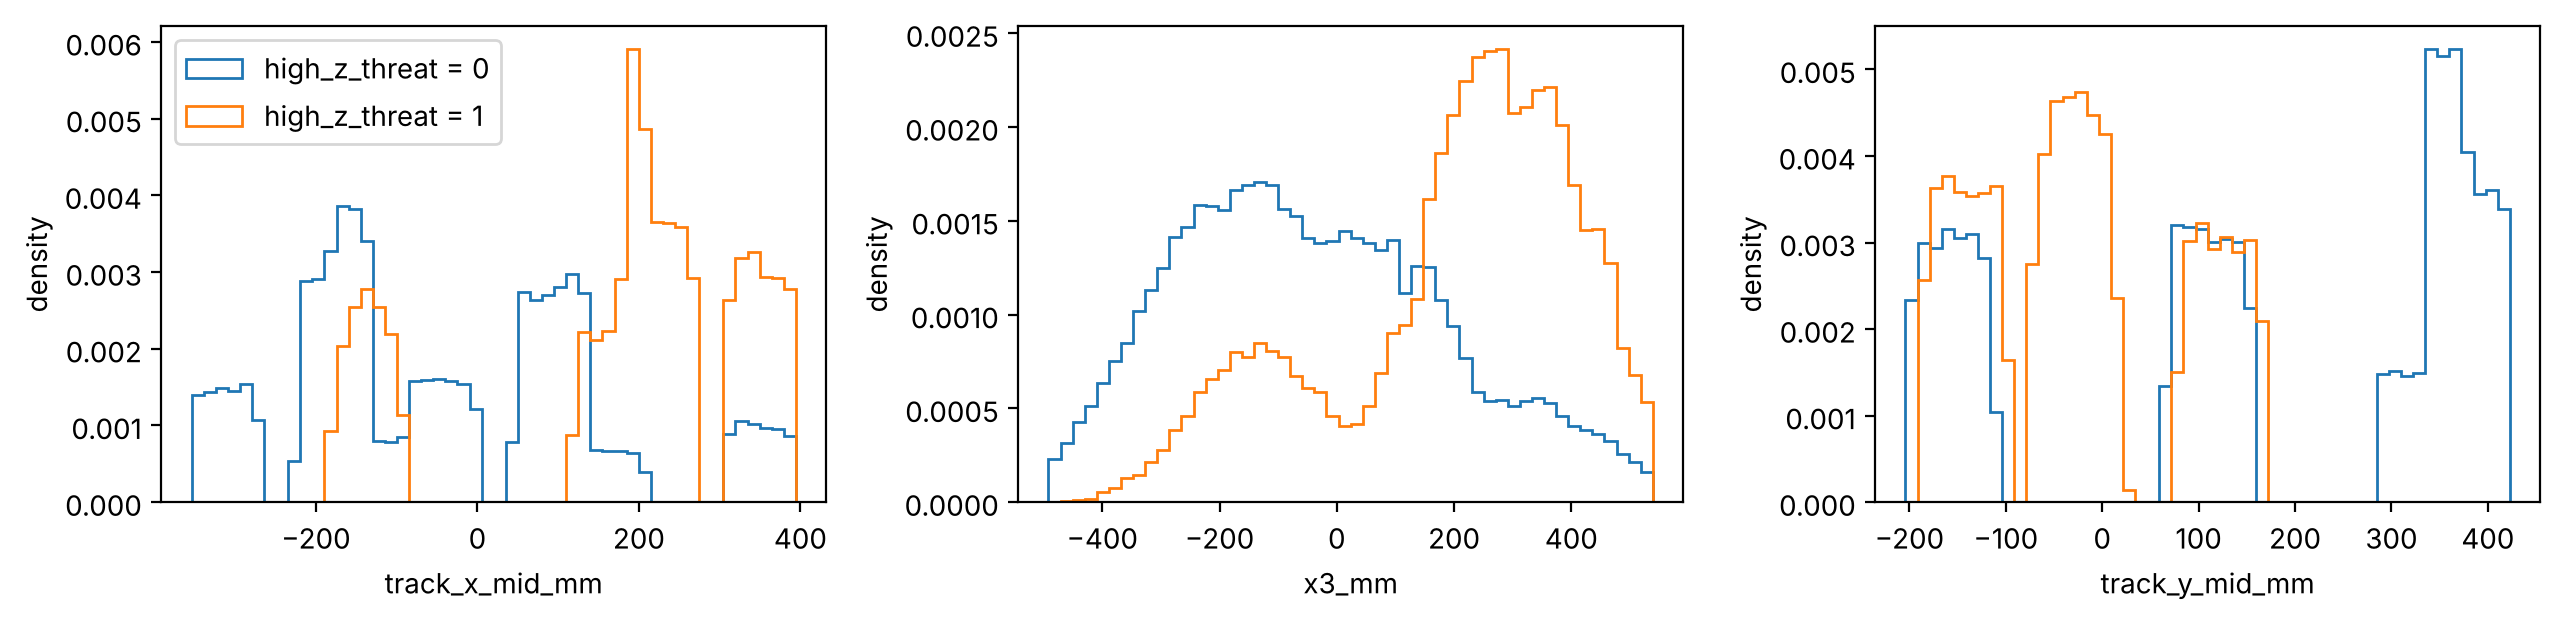

In [9]:
location_used = [c for c in location if c not in constants]
ks_location = ks_table(df, location_used, TARGET)
display(ks_location.head(5).round(3).to_frame())
top_location = list(ks_location.index[:3])
compare_hist(df, top_location, TARGET, BINS, PLOT_RANGE_QUANTILES)

**Notes.** The location features separate the classes **much more strongly** than any physics feature. A column that looks that good is a warning, not a gift: the machine-learning method "will do the easy thing if it can". We come back to this in Section 8.

## 4. Clean and prepare

### 4.1 Missing values

Only `atomic_number_Z` had missing values, and it is a label leak that we drop. Checking the features:

In [10]:
print("missing values in the features:", int(df[candidates].isna().sum().sum()))

missing values in the features: 0


### 4.2 Outliers

An outlier is not "anything beyond some quantile": on a smooth distribution that just cuts the tails, and the tails are data. An outlier is a value that comes from something broken or something we weren't accounting for. Here is one candidate with a physical definition:

> **Candidate outlier:** the PoCA point (where the muon is assumed to have scattered) lies **outside the box spanned by the detector hits**. A scattering point outside the detector can't be right.

The box is computed from the data, not typed in.

In [11]:
outside = outside_detector(df, AXES, POCA_TEMPLATE, HIT_TEMPLATE)
print(f"{outside.mean():.1%} of muons have a PoCA point outside the detector")
summary = df.groupby(outside)[candidates].median().rename(index={False: "inside", True: "outside"})
summary["share of class 1"] = df.groupby(outside)[TARGET].mean().values
display(summary.round(3))

13.4% of muons have a PoCA point outside the detector


,theta_mrad,theta_x_mrad,theta_y_mrad,dca_mm,zenith_in_deg,share of class 1
inside,20.547,6.24,0.308,4.793,21.029,0.284
outside,5.610,1.54,0.038,4.448,22.535,0.139


**Why we keep them.** These muons have a much *smaller* scattering angle than the rest. That makes sense: when the incoming and outgoing tracks are almost parallel, the lines barely cross, and the "closest point" can land far away. They are not broken muons; they are the **least scattered** ones. Removing them would throw away exactly the muons that look "light" and bias what is left. Their PoCA *coordinates* are unreliable, but we don't use those coordinates as features. Section 6 checks what happens if we remove them anyway.

The long tail of large scattering angles is real physics too (rare big deflections), so it stays. Mistakes here are fine as long as the decision is stated and checked.

### 4.3 One-hot encoding

Categorical features with more than two values need one-hot encoding. The code checks whether any categorical feature is left among the candidates:

In [12]:
categorical = [c for c in candidates if not pd.api.types.is_numeric_dtype(df[c])]
X = pd.get_dummies(df[candidates], columns=categorical, dtype=int)
features = list(X.columns)
if categorical:
    print(f"one-hot encoded {categorical}: {len(candidates)} columns became {len(features)}")
else:
    print("no categorical features are left (the only categories were label leaks), so nothing to one-hot encode")
print("features used by the models:", features)

no categorical features are left (the only categories were label leaks), so nothing to one-hot encode
features used by the models: ['theta_mrad', 'theta_x_mrad', 'theta_y_mrad', 'dca_mm', 'zenith_in_deg']


## 5. Problem formulation and split

* **Inputs (X):** the physics features above. **Output (y):** the target.
* **Removed:** label leaks, constants, bookkeeping and location columns. The row counter `muon_id` is an identifier: a model given an ID can memorize it instead of learning.
* **Split:** train / validation / test with the fractions in the settings, stratified so each part has the same class mix. The **validation** part is for making choices; the **test** part is looked at once, at the end.

In [13]:
data = pd.concat([X, df[TARGET]], axis=1)
train, val, test = three_way_split(data, TARGET, SPLIT, SEED)
sizes = pd.DataFrame({"muons": [len(train), len(val), len(test)],
                      "fraction of class 1": [d[TARGET].mean() for d in (train, val, test)]},
                     index=["train", "validation", "test"])
display(sizes.round(3))

,muons,fraction of class 1
train,119644,0.265
validation,14956,0.265
test,14956,0.265


### Scaling

Logistic regression is sensitive to the scale of its inputs, so each feature is **standardized** (subtract the mean, divide by the standard deviation). The scaler is learned from the **training** part only and travels inside the model, so the validation and test parts never leak into it. Decision trees ignore scale, so they don't need it.

Look before and after (training part), as the course asks:

before:


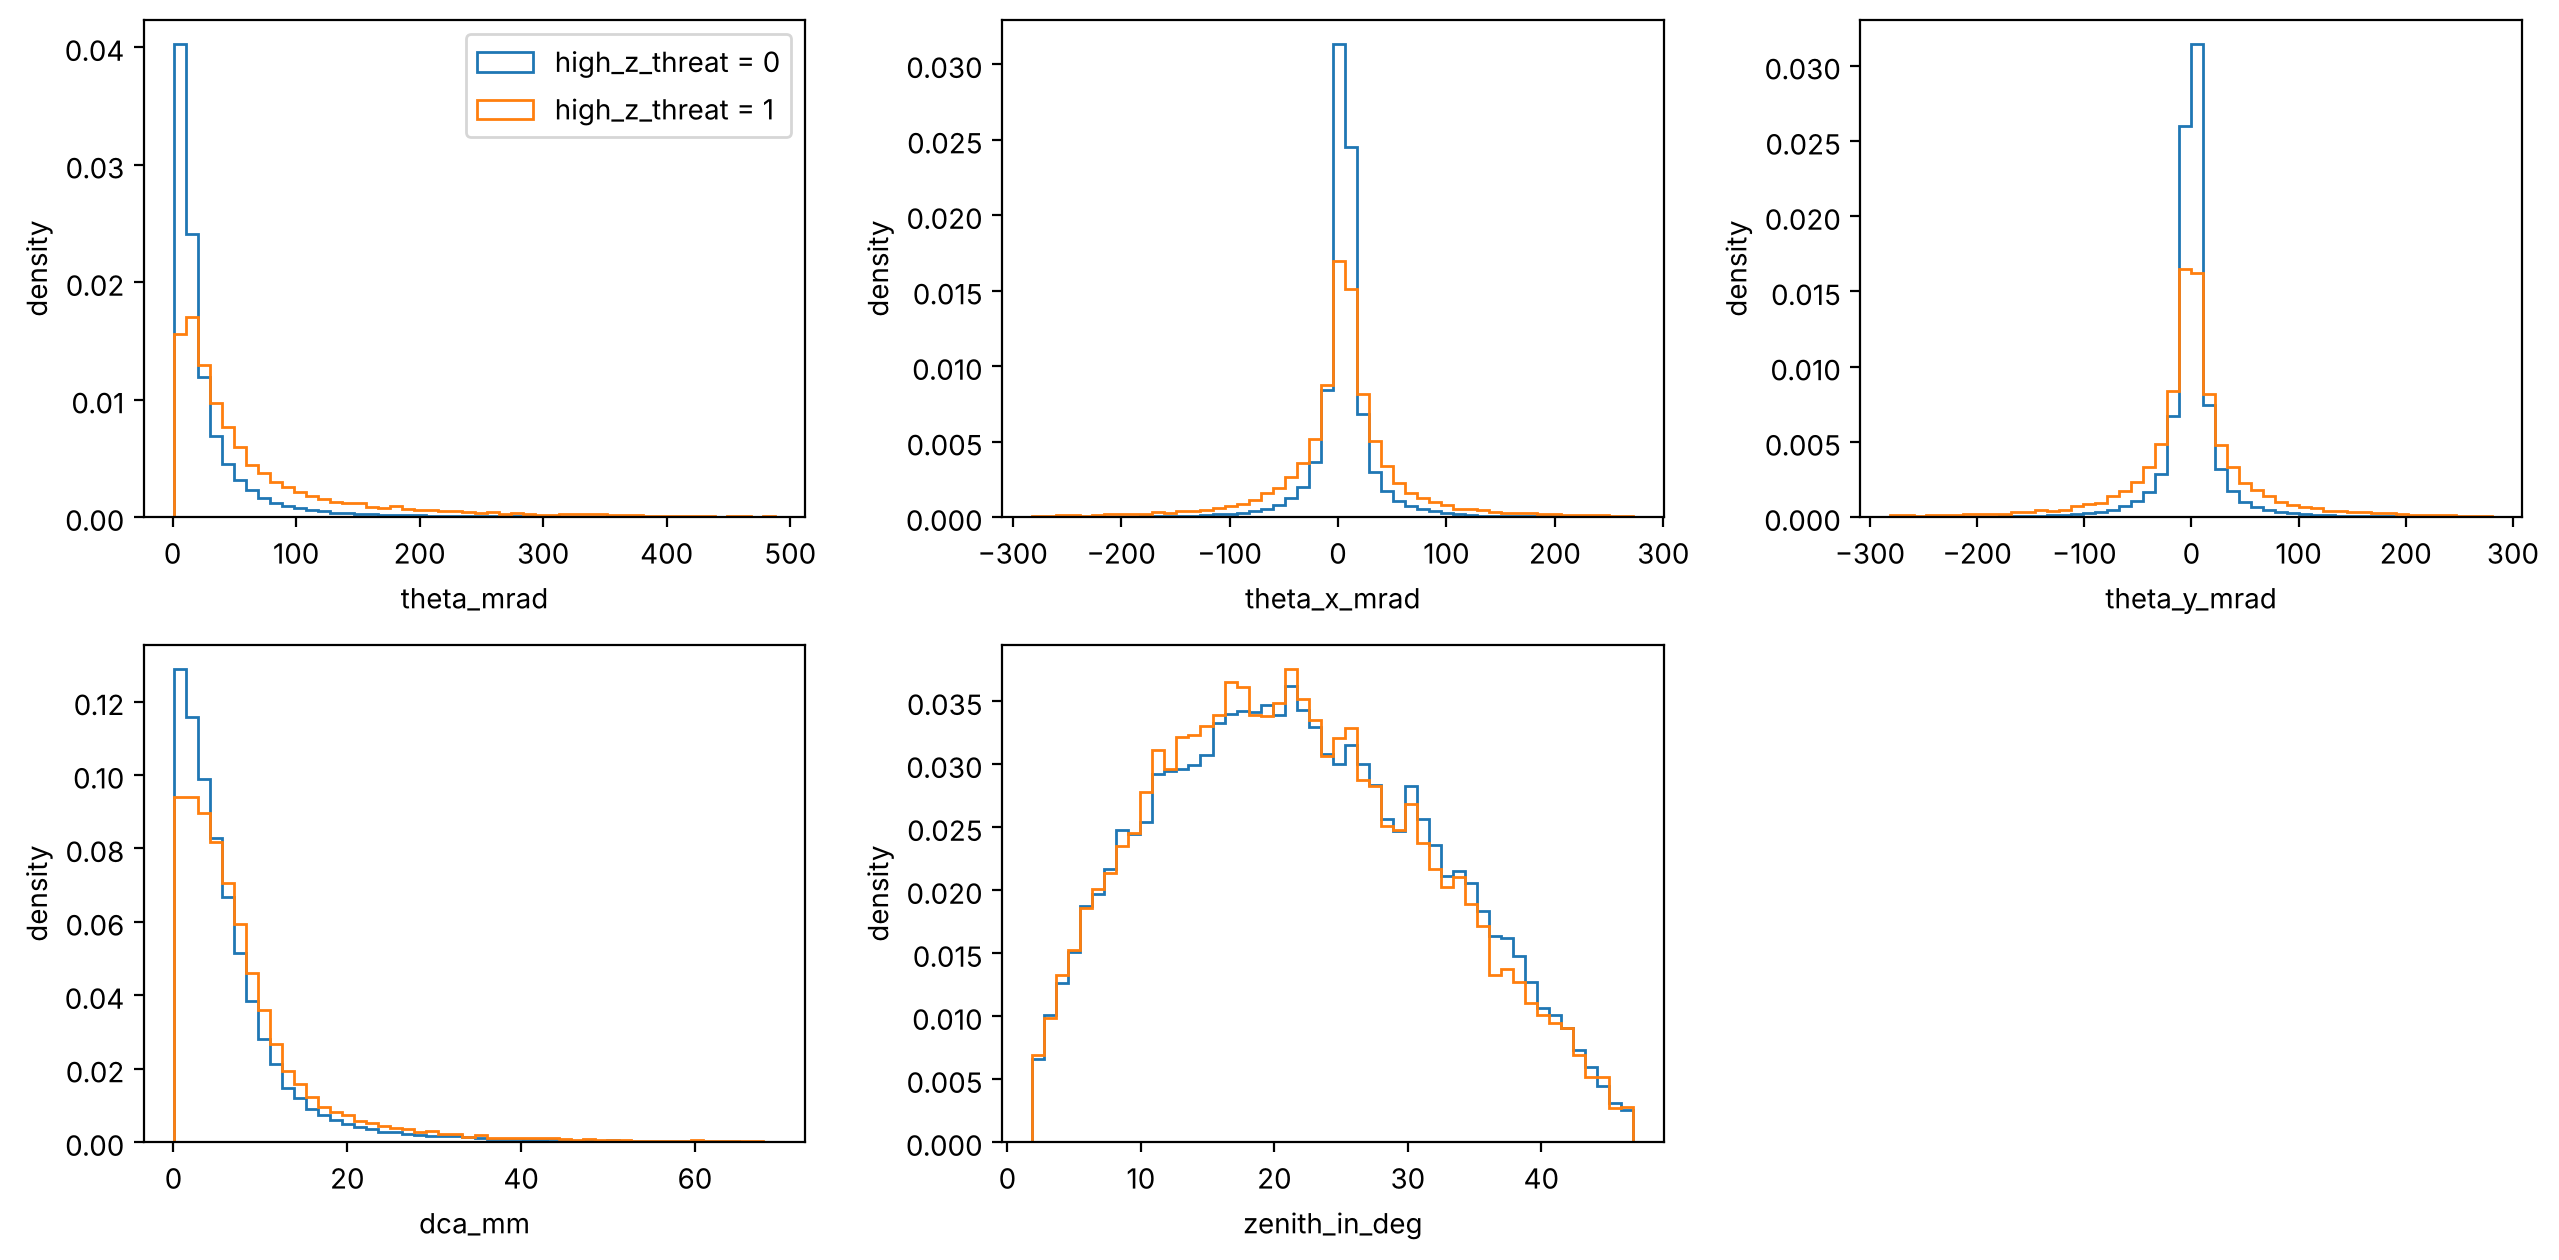

after:


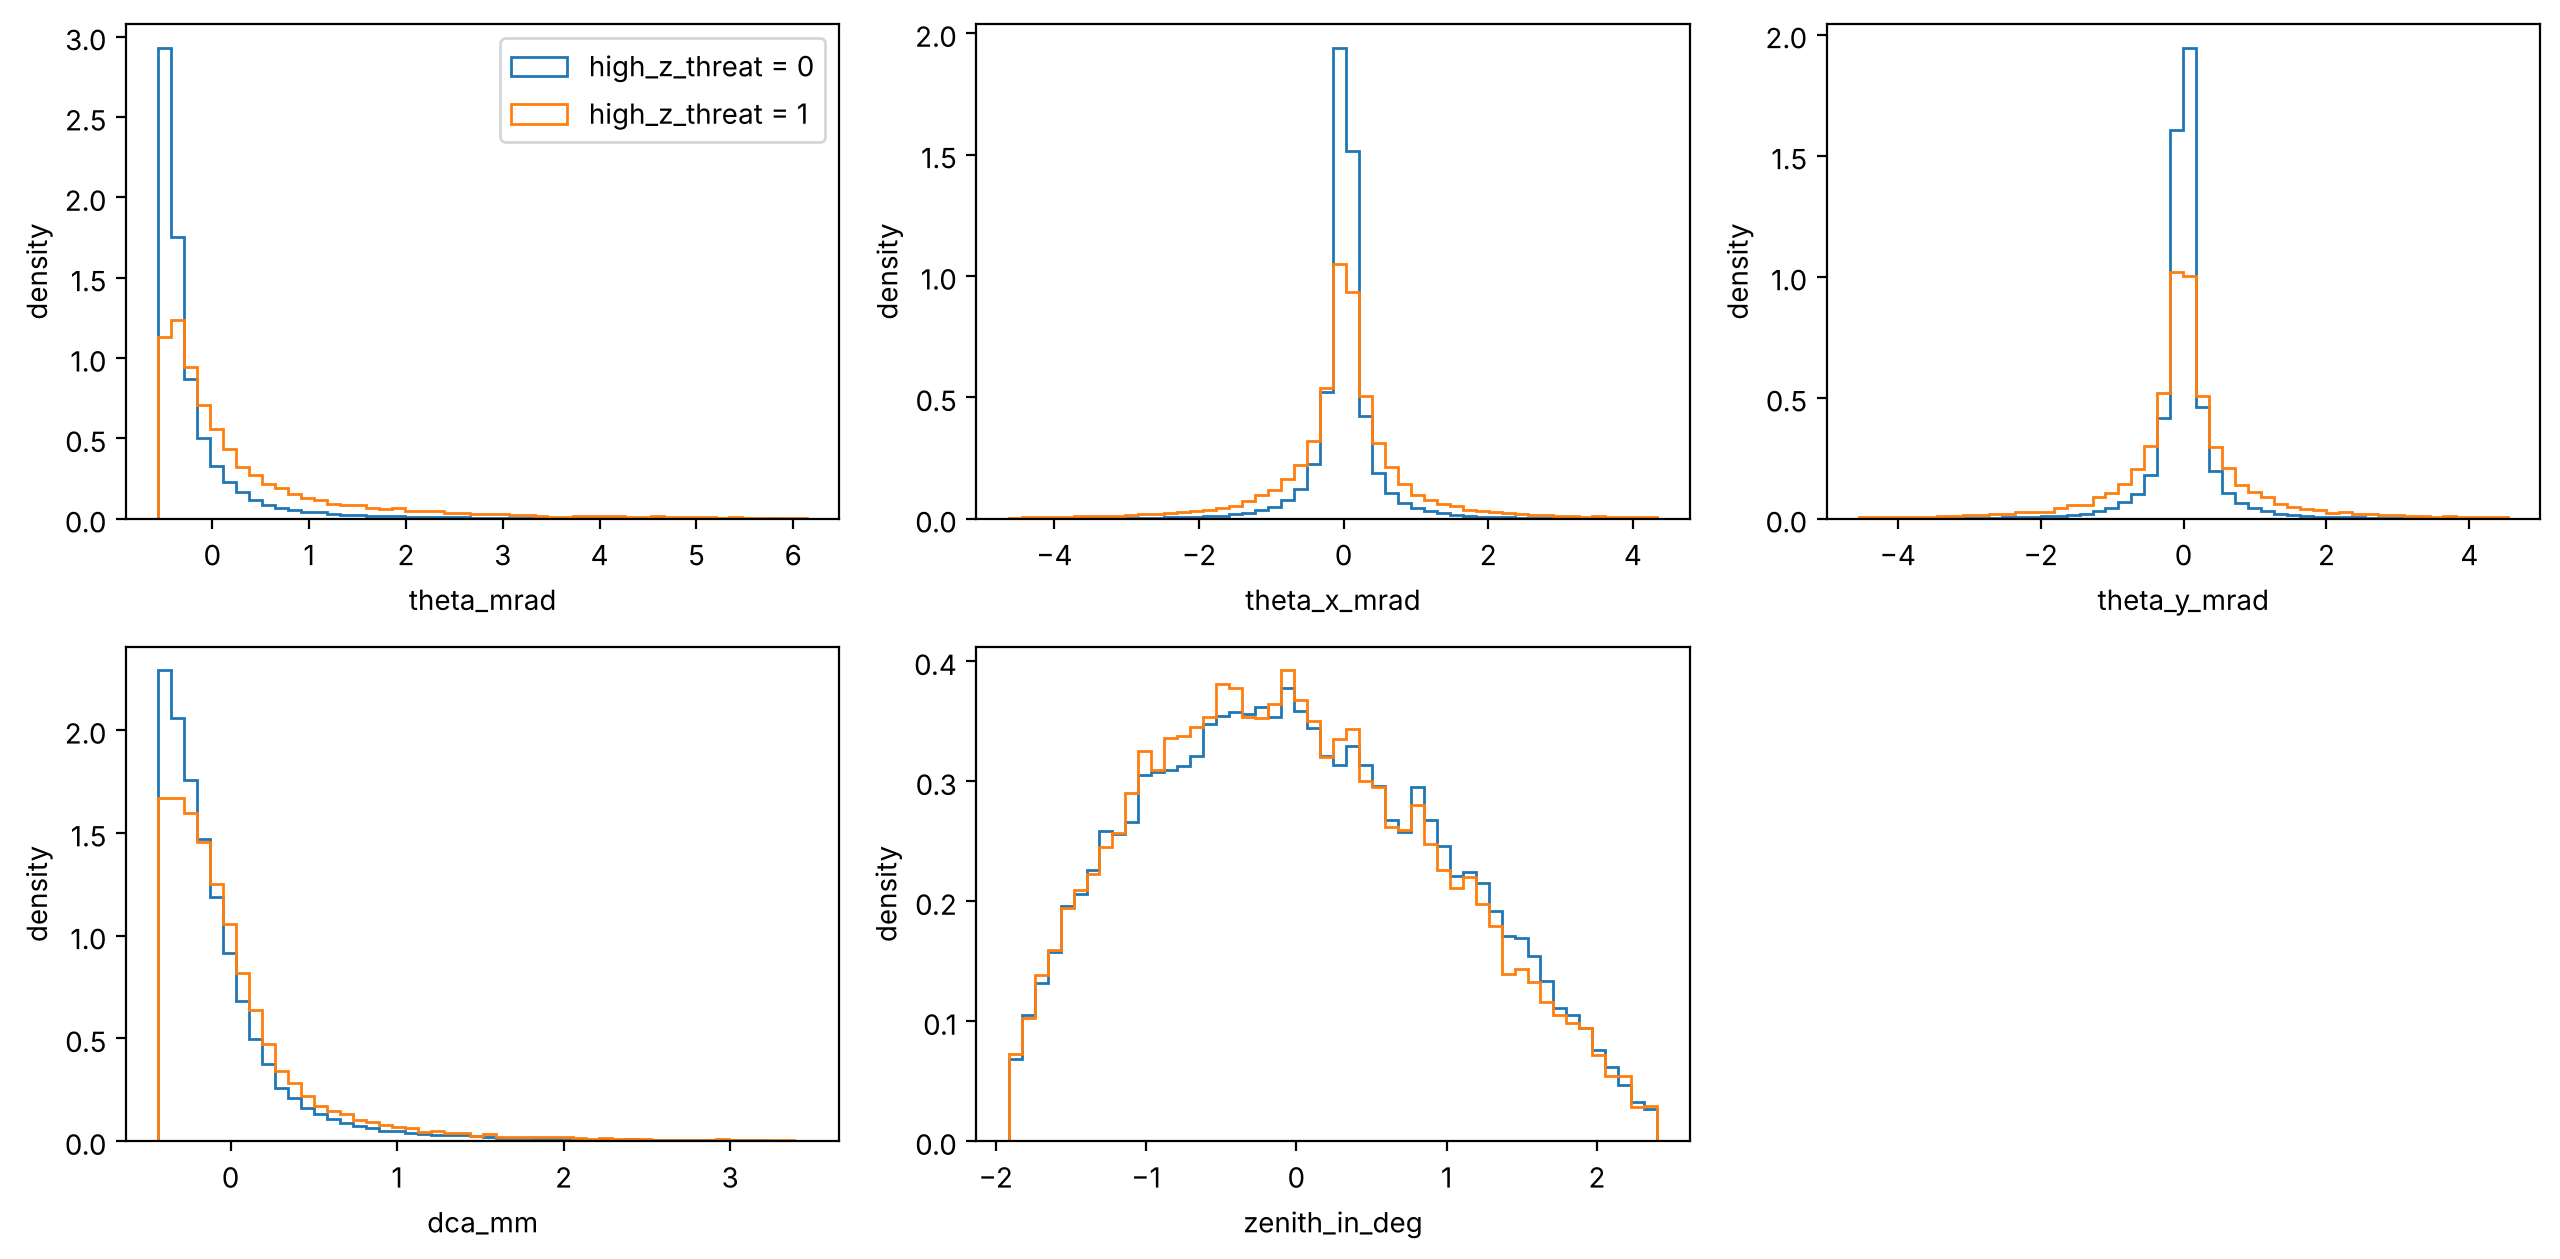

In [14]:
scaler = StandardScaler().fit(train[features])
scaled = pd.DataFrame(scaler.transform(train[features]), columns=features, index=train.index)
scaled[TARGET] = train[TARGET]
print("before:")
compare_hist(train, features, TARGET, BINS, PLOT_RANGE_QUANTILES)
print("after:")
compare_hist(scaled, features, TARGET, BINS, PLOT_RANGE_QUANTILES)

The shapes are unchanged; only the axes moved (each feature now has mean 0 and standard deviation 1). That is what we meant to do.

## 6. Baselines, then simple models

A baseline tells us whether a fancier model is earning its keep:

1. **Always answer "no"** (the most common class).
2. **One feature only:** the single best feature, chosen from the *training* part.
3. **Logistic regression** on the standardized features, with and without class weights.
4. **Decision tree**, with its depth chosen on the validation part.
5. **Random forest** (many small trees voting).

### The tree depth: reading the curves

,max_depth,train AUC,validation AUC
0,2,0.695,0.697
1,3,0.705,0.708
2,4,0.711,0.713
3,5,0.716,0.716
4,6,0.720,0.716
5,8,0.730,0.719
6,10,0.747,0.714
7,14,0.811,0.670


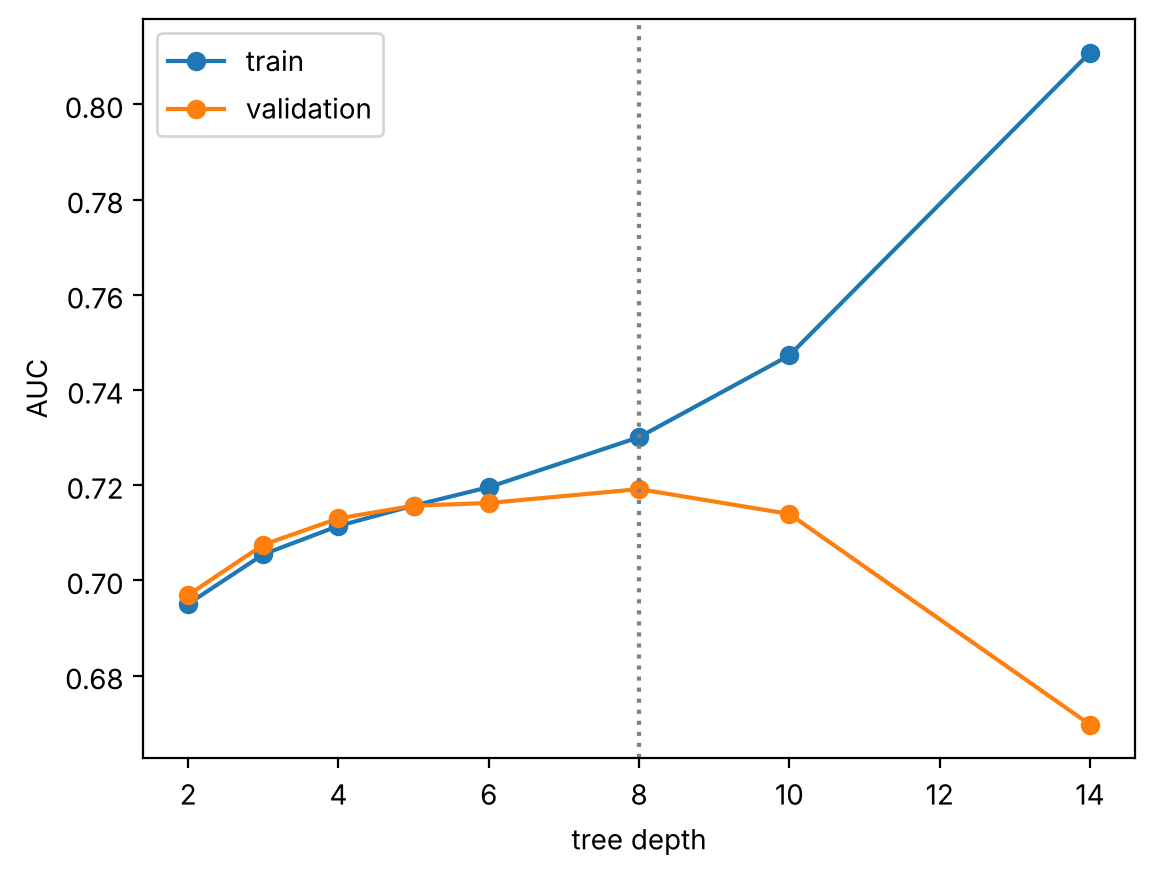

depth chosen on the validation part: 8


In [15]:
scan = []
for depth in TREE_DEPTHS:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(train[features], train[TARGET])
    scan.append({"max_depth": depth,
                 "train AUC": roc_auc_score(train[TARGET], tree.predict_proba(train[features])[:, 1]),
                 "validation AUC": roc_auc_score(val[TARGET], tree.predict_proba(val[features])[:, 1])})
scan = pd.DataFrame(scan)
best_depth = int(scan.loc[scan["validation AUC"].idxmax(), "max_depth"])
display(scan.round(3))
plt.plot(scan["max_depth"], scan["train AUC"], marker="o", label="train")
plt.plot(scan["max_depth"], scan["validation AUC"], marker="o", label="validation")
plt.axvline(best_depth, linestyle=":", color="gray")
plt.xlabel("tree depth"); plt.ylabel("AUC"); plt.legend()
plt.show()
print("depth chosen on the validation part:", best_depth)

A very deep tree keeps improving on the training part but stops improving (or gets worse) on the validation part: it is memorizing its training sample. This is the same **over-training** pattern the lecture shows with the neural network's loss curves. We stop where the validation curve peaks.

In [16]:
best_feature = ks_table(train, features, TARGET).index[0]      # chosen from the training part only
print("best single feature:", best_feature)

models = {
    "always answer 'no'": ("baseline", DummyClassifier(strategy="prior"), features),
    f"one feature ({best_feature})": ("baseline", make_pipeline(StandardScaler(), LogisticRegression(max_iter=MAX_ITER)), [best_feature]),
    "logistic regression": ("model", make_pipeline(StandardScaler(), LogisticRegression(max_iter=MAX_ITER)), features),
    "logistic regression (class weights)": ("model", make_pipeline(StandardScaler(), LogisticRegression(max_iter=MAX_ITER, class_weight="balanced")), features),
    f"decision tree (depth {best_depth})": ("model", DecisionTreeClassifier(max_depth=best_depth, random_state=SEED), features),
    "random forest": ("model", RandomForestClassifier(n_estimators=FOREST_TREES, min_samples_leaf=FOREST_MIN_LEAF,
                                                      n_jobs=-1, random_state=SEED), features),
}

rows = []
for name, (kind, model, cols) in models.items():
    model.fit(train[cols], train[TARGET])
    row = {"model": name, "kind": kind,
           "train AUC": roc_auc_score(train[TARGET], model.predict_proba(train[cols])[:, 1])}
    row.update({f"validation {k}": v for k, v in
                evaluate(val[TARGET], model.predict_proba(val[cols])[:, 1], FALSE_ALARM_RATE, THRESHOLD).items()})
    rows.append(row)
results = pd.DataFrame(rows).set_index("model")
display(results.drop(columns="kind").round(3))
print(f"recall@FA = recall when we allow {FALSE_ALARM_RATE:.0%} false alarms;  accuracy, recall, precision use a threshold of {THRESHOLD}")

best single feature: theta_mrad


,train AUC,validation AUC,validation recall@FA,validation accuracy,validation recall,validation precision
model,,,,,,
always answer 'no',0.500,0.500,0.050,0.735,0.000,NaN
one feature (theta_mrad),0.707,0.711,0.181,0.743,0.092,0.586
logistic regression,0.696,0.699,0.181,0.743,0.095,0.591
logistic regression (class weights),0.703,0.706,0.181,0.727,0.427,0.483
decision tree (depth 8),0.730,0.719,0.199,0.751,0.213,0.582
random forest,0.780,0.727,0.208,0.753,0.227,0.585


recall@FA = recall when we allow 5% false alarms;  accuracy, recall, precision use a threshold of 0.5


**Reading the table.**

* **Always answer "no"** has a respectable accuracy and a recall of zero: it never catches a single high-Z muon. This is the imbalance trap in numbers.
* The **one-feature** baseline already does clearly better than chance. Everything else has to beat it, and the gain turns out to be small.
* The models are close to each other. With only a handful of noisy features, there isn't much for a fancier model to find. Compare the **train** and **validation** AUC for signs of over-training.
* At the default threshold, the models without class weights flag very few high-Z muons (low recall), because high-Z is the minority class and scores rarely pass the threshold. Class weights catch many more of them at the cost of precision, while the AUC barely changes.

In [17]:
chosen = results[results["kind"] == "model"]["validation AUC"].idxmax()
print("chosen on the validation part:", chosen)

chosen on the validation part: random forest


### Outlier decision check: what if we remove the "outside the detector" muons?

We kept them. As a check, train the same logistic regression without them and compare on the same validation part:

In [18]:
lr_cols = features
keep = ~outside.loc[train.index]
lr_all = make_pipeline(StandardScaler(), LogisticRegression(max_iter=MAX_ITER)).fit(train[lr_cols], train[TARGET])
lr_trimmed = make_pipeline(StandardScaler(), LogisticRegression(max_iter=MAX_ITER)).fit(train.loc[keep, lr_cols], train.loc[keep, TARGET])
check = pd.Series({
    "kept (our choice)": roc_auc_score(val[TARGET], lr_all.predict_proba(val[lr_cols])[:, 1]),
    "removed from training": roc_auc_score(val[TARGET], lr_trimmed.predict_proba(val[lr_cols])[:, 1])}, name="validation AUC")
display(check.round(4).to_frame())

,validation AUC
kept (our choice),0.6988
removed from training,0.7015


The two scores are almost the same, so the score alone doesn't settle it. We keep the muons for a reason that doesn't depend on the score: they are real, nearly straight muons, and the validation part, the test part and any future measurement contain them too, so the model should learn from them. If this check had shown a big change, we would revisit the decision.

## 7. Evaluate: the chosen model on the test part

The choice was made on the validation part. Now the **test** part is used once, to report. Always look at the model's output for the two classes: "you can immediately tell if it's working or not".

,AUC,recall@FA,accuracy,recall,precision
always answer 'no',0.500,0.050,0.735,0.000,NaN
one feature (theta_mrad),0.712,0.194,0.742,0.089,0.583
logistic regression,0.703,0.198,0.744,0.095,0.601
logistic regression (class weights),0.709,0.197,0.732,0.425,0.493
decision tree (depth 8),0.717,0.203,0.752,0.200,0.595
random forest,0.725,0.219,0.757,0.218,0.615


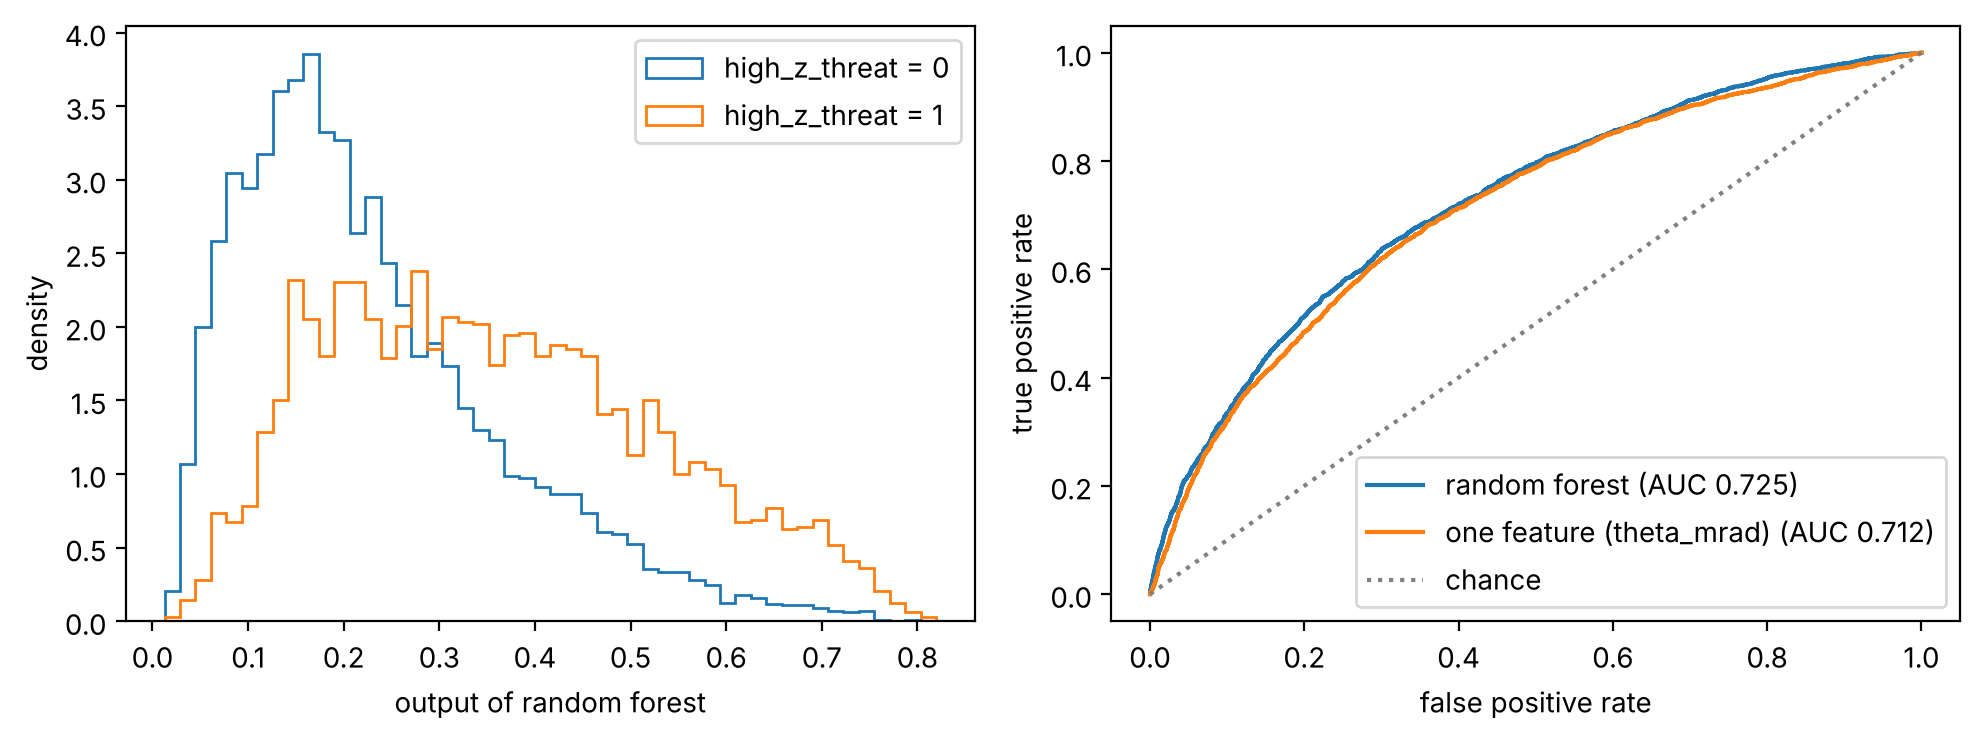

confusion matrix at threshold 0.5:  TP=864  FN=3093  FP=542  TN=10457


In [19]:
best_model = models[chosen][1]
test_score = best_model.predict_proba(test[features])[:, 1]
final = {name: evaluate(test[TARGET], m.predict_proba(test[c])[:, 1], FALSE_ALARM_RATE, THRESHOLD)
         for name, (_, m, c) in models.items()}
final = pd.DataFrame(final).T
display(final.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
edges = np.linspace(test_score.min(), test_score.max(), BINS + 1)
for cls in sorted(test[TARGET].unique()):
    axes[0].hist(test_score[(test[TARGET] == cls).to_numpy()], bins=edges, density=True,
                 histtype="step", label=f"{TARGET} = {cls}")
axes[0].set_xlabel(f"output of {chosen}"); axes[0].set_ylabel("density"); axes[0].legend()
for name in [chosen, f"one feature ({best_feature})"]:
    _, m, c = models[name]
    fpr, tpr, _ = roc_curve(test[TARGET], m.predict_proba(test[c])[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(test[TARGET], m.predict_proba(test[c])[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], linestyle=":", color="gray", label="chance")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(test[TARGET], test_score >= THRESHOLD, labels=np.unique(test[TARGET])).ravel()
print(f"confusion matrix at threshold {THRESHOLD}:  TP={tp}  FN={fn}  FP={fp}  TN={tn}")

**Notes.** The two score distributions overlap a lot: one muon is a weak witness. The ROC curve is clearly above chance but far from perfect. That is an honest, **non-trivial** result, better than the baseline but nowhere near perfect, and it is what the physics predicts, because a single muon's scattering angle depends on its (unknown) energy as well as on the material.

## 8. Sanity check: what if we feed the model *everything*?

"Be suspicious of results that are too good." Add the location columns we set aside and see what happens:

In [20]:
leaky = features + location_used
leaky_models = {
    "decision tree": DecisionTreeClassifier(max_depth=best_depth, random_state=SEED),
    "random forest": RandomForestClassifier(n_estimators=FOREST_TREES, min_samples_leaf=FOREST_MIN_LEAF, n_jobs=-1, random_state=SEED)}
rows = {}
for name, model in leaky_models.items():
    scores = {}
    for label, cols in [("physics only", features), ("physics + location", leaky)]:
        model.fit(df.loc[train.index, cols], train[TARGET])
        scores[label] = roc_auc_score(val[TARGET], model.predict_proba(df.loc[val.index, cols])[:, 1])
    rows[name] = scores
display(pd.DataFrame(rows).T.round(3))
importance = pd.Series(leaky_models["decision tree"].feature_importances_, index=leaky).sort_values(ascending=False)
display(importance.head(5).round(3).to_frame("tree importance"))

,physics only,physics + location
decision tree,0.719,1.0
random forest,0.727,1.0


,tree importance
track_y_mid_mm,0.647
track_x_mid_mm,0.353
theta_x_mrad,0.000
theta_mrad,0.000
theta_y_mrad,0.000


**This is a leak.** With location included, the scores jump to nearly perfect, and the most important features are positions, not physics. Why? Look at the map of the experiment:

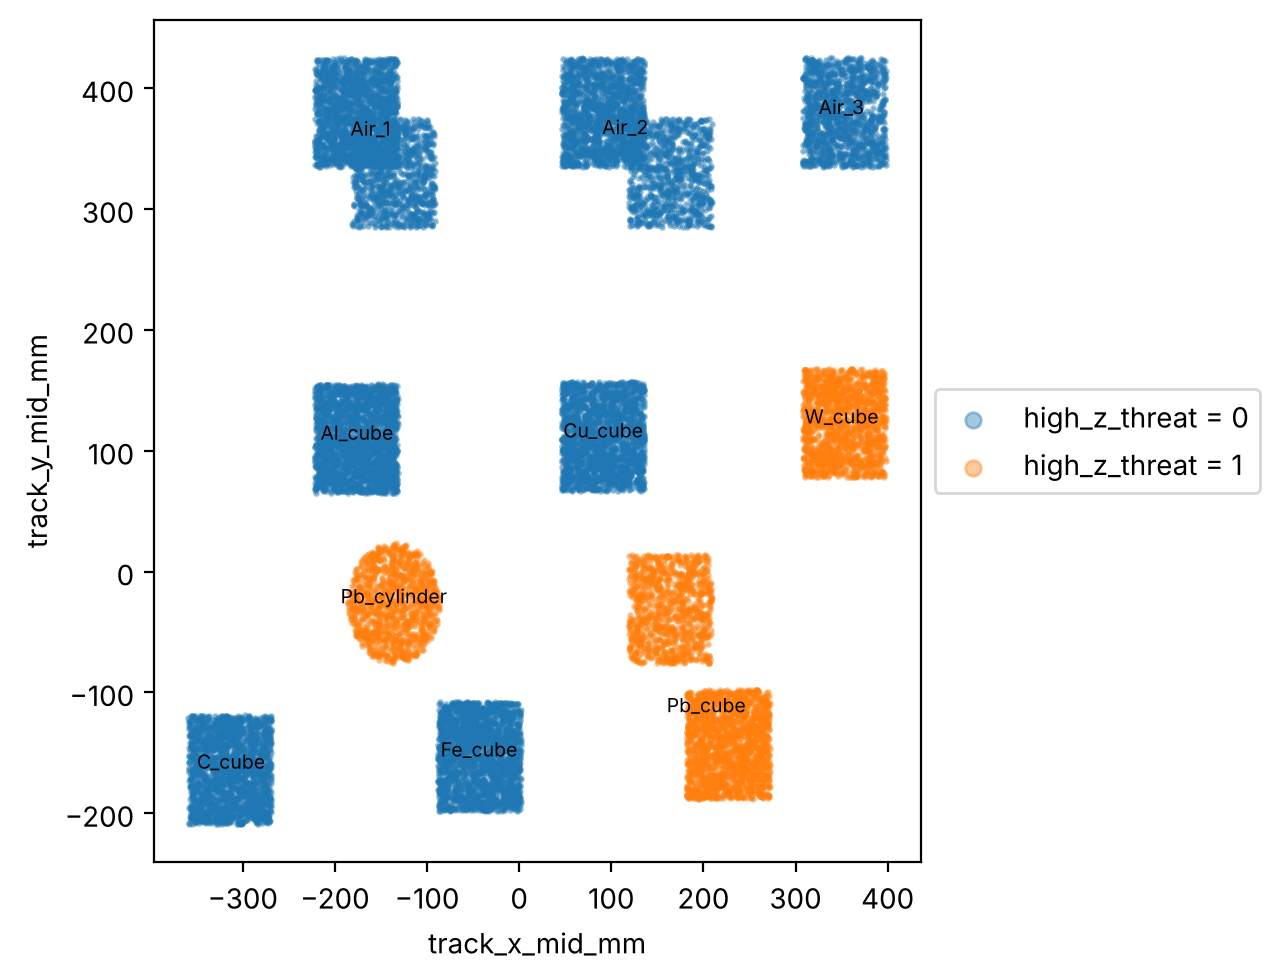

In [21]:
sample = df.sample(MAP_SAMPLE, random_state=SEED)
fig, ax = plt.subplots(figsize=(6.5, 5))
for cls in sorted(df[TARGET].unique()):
    s = sample[sample[TARGET] == cls]
    ax.scatter(s[MAP_COLUMNS[0]], s[MAP_COLUMNS[1]], s=2, alpha=0.4, label=f"{TARGET} = {cls}")
for name, g in df.groupby(OBJECT_COLUMN):
    ax.text(g[MAP_COLUMNS[0]].median(), g[MAP_COLUMNS[1]].median(), name, fontsize=7, ha="center")
ax.set_xlabel(MAP_COLUMNS[0]); ax.set_ylabel(MAP_COLUMNS[1]); ax.legend(markerscale=4, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

Every object sits in its own spot, so **where** the muon crossed tells you **which object** it crossed. A model with location learns "this corner of the floor holds lead", not "lead bends muons more". Move the blocks and it would fail completely. That is why the location features stay out, and why the honest per-muon score above is the one to trust.

This is also exactly why the paper does it in two stages: first **find where the objects are** (DBSCAN), *then* identify the material from the scattering. Location is the first step's job, not the classifier's.

## 9. Bridge to the paper: combine many muons

One muon is a noisy witness, but the paper measures for minutes and uses **statistics over many muons**. We can mimic that: group the muons of one object that arrived in the same time window, and summarize them (mean and standard deviation of each physics feature). One row now describes a *measurement of a given length*. Longer windows contain more muons.

Two honest notes: grouping by `object` uses the file's own label of which object each muon crossed (the paper finds the objects with DBSCAN instead), and we leave out the **number of muons** as a feature, because it may reflect the object's size and position rather than its material.

model,decision tree,logistic regression
minutes,,
0.5,0.868,0.904
1.0,0.903,0.948
2.0,0.913,0.982
5.0,0.942,0.994
10.0,0.963,1.000


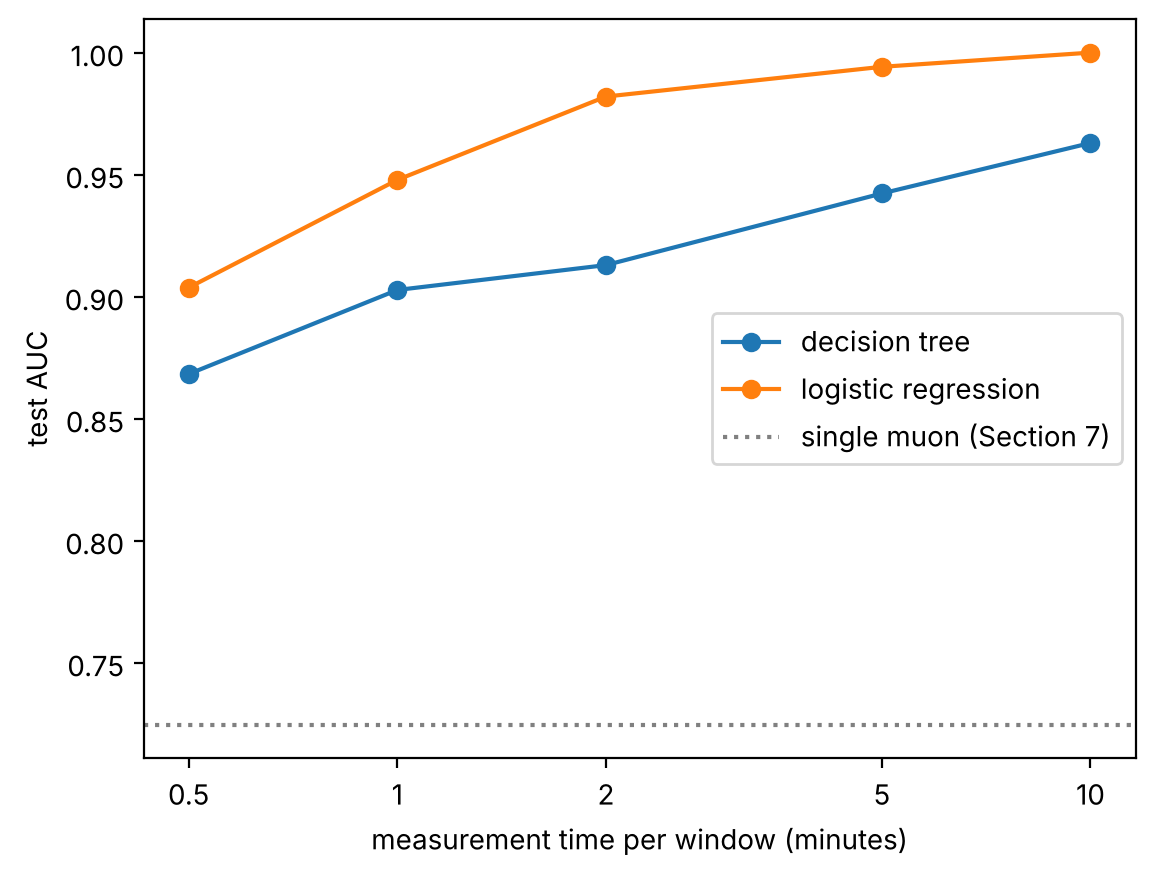

,minutes,windows,median muons per window
0,0.5,18898,8.0
1,1.0,9505,16.0
2,2.0,4753,31.0
3,5.0,1903,79.0
4,10.0,956,158.0


KS statistic of the muon count alone (longest windows): 0.33 (0 = no difference between the classes)


In [22]:
window_rows = []
for minutes in WINDOW_MINUTES:
    windows = make_windows(df, [EXPERIMENT_COLUMN, OBJECT_COLUMN], TIME_COLUMN, minutes, features, TARGET, MIN_MUONS_PER_WINDOW)
    w_features = [c for c in windows.columns if c not in (TARGET, "n_muons")]
    w_train, w_val, w_test = three_way_split(windows, TARGET, SPLIT, SEED)
    for name, model in [("logistic regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=MAX_ITER))),
                        ("decision tree", DecisionTreeClassifier(max_depth=best_depth, random_state=SEED))]:
        model.fit(w_train[w_features], w_train[TARGET])
        window_rows.append({"minutes": minutes, "model": name, "windows": len(windows),
                            "median muons per window": windows["n_muons"].median(),
                            "test AUC": roc_auc_score(w_test[TARGET], model.predict_proba(w_test[w_features])[:, 1])})
window_results = pd.DataFrame(window_rows)
display(window_results.pivot(index="minutes", columns="model", values="test AUC").round(3))

for name, g in window_results.groupby("model"):
    plt.plot(g["minutes"], g["test AUC"], marker="o", label=name)
per_muon_auc = final.loc[chosen, "AUC"]
plt.axhline(per_muon_auc, linestyle=":", color="gray", label="single muon (Section 7)")
plt.xscale("log"); plt.xticks(WINDOW_MINUTES, WINDOW_MINUTES); plt.minorticks_off()
plt.xlabel("measurement time per window (minutes)"); plt.ylabel("test AUC"); plt.legend()
plt.show()

counts = window_results[window_results["model"] == window_results["model"].iloc[0]]
display(counts[["minutes", "windows", "median muons per window"]].reset_index(drop=True))
print(f"KS statistic of the muon count alone (longest windows): {ks_table(windows, ['n_muons'], TARGET).iloc[0]:.2f}"
      " (0 = no difference between the classes)")

**Notes.** The longer the measurement, the more muons per window and the better the separation. This is the same trade-off as in the paper (recall rising with measurement time), reproduced from the muon-level data. The test sets here are small (especially for long windows, where there are few windows), so treat small differences as noise.

## 10. Summary

In [23]:
best_row = final.loc[chosen]
baseline_row = final.loc[f"one feature ({best_feature})"]
longest = window_results[window_results["minutes"] == window_results["minutes"].max()]
shortest = window_results[window_results["minutes"] == window_results["minutes"].min()]
display(Markdown(f"""
* **Data:** {len(df):,} muons, {len(features)} physics features, {df[TARGET].mean():.0%} of muons in the high-Z class.
* **Single muon:** the best simple model on the validation part was **{chosen}**; on the test part its AUC is **{best_row['AUC']:.3f}**, against {baseline_row['AUC']:.3f} for the best single feature and 0.5 for chance.
* **Many muons:** with the shortest window ({shortest['minutes'].iloc[0]} min) the best test AUC is {shortest['test AUC'].max():.3f}; with the longest ({longest['minutes'].iloc[0]} min) it is {longest['test AUC'].max():.3f}.
* **The trap:** adding location columns pushes the single-muon score to nearly perfect, but only because each object sits in a fixed place.
"""))


* **Data:** 149,556 muons, 5 physics features, 26% of muons in the high-Z class.
* **Single muon:** the best simple model on the validation part was **random forest**; on the test part its AUC is **0.725**, against 0.712 for the best single feature and 0.5 for chance.
* **Many muons:** with the shortest window (0.5 min) the best test AUC is 0.904; with the longest (10.0 min) it is 1.000.
* **The trap:** adding location columns pushes the single-muon score to nearly perfect, but only because each object sits in a fixed place.


### What I would say in a README

* **One sentence:** simple models separate high-Z from other materials using muon scattering, modestly for one muon and very well when many muons are combined.
* **The lesson in the data:** the best-looking features (location) were the ones that cheated.
* **What didn't work / difficulties:** one muon alone is a weak witness; the outlier idea ("PoCA outside the detector") turned out to flag the *least* scattered muons, so we kept them.
* **Limits:** small test sets in the window section; one random split; no cross-validation; the objects are clean cubes with no shielding.

### What a real submission still needs

* A **Kaggle competition** dataset with a leaderboard score, and a retrain on all of `train` before predicting Kaggle's `test` file.
* The helper functions moved into a **module**, and the notebook split into clean notebooks (first look and plots, models, submission).
* A **README** in your own words, a **requirements** file, and the data kept out of GitHub.
* Optionally, a boosted-tree model (not used in this draft) and a few repeats with different seeds to see how much the scores wobble.

**Reproducibility check:** *Kernel → Restart & Run All* should give the same notebook from top to bottom.